# FINAL PROJECT: Aspect-Based Sentiment Analysis for Skincare Reviews

## **PHASE 1: PREPROCESSING AND EXPLORATORY DATA ANALYSIS (EDA)**

The goal of this phase is to prepare a clean dataset for the aspect-based sentiment analysis model. Each preprocessing step is supported by exploratory analysis to make sure that cleaning decisions keep meaningful customer opinions while removing noise and duplicate information.

In [1]:
# Imports
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import re
import html
from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException

### Step 1: Download the dataset from Kaggle
Download the Sephora reviews and product metadata from Kaggle

In [2]:
# Download and unzip the dataset (skips re-download/re-extract if files already exist)
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)

!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download nadyinky/sephora-products-and-skincare-reviews
!unzip -n sephora-products-and-skincare-reviews.zip

Dataset URL: https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews
License(s): Attribution 4.0 International (CC BY 4.0)
sephora-products-and-skincare-reviews.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  sephora-products-and-skincare-reviews.zip


### Step 2: Load reviews + product metadata, and merge them

Merge chunks into a single dataset using product_id. Verify that every review matches a product and confirm that no rows are lost during the merge.

In [ ]:
# Load all review CSV chunks and combine them into one dataset.
review_files = glob.glob("reviews_*.csv")
reviews = pd.concat(
    [pd.read_csv(f, dtype={"author_id": str}, low_memory=False) for f in review_files],
    ignore_index=True
)

# Load product metadata
products = pd.read_csv("product_info.csv", dtype={"product_id": str}, low_memory=False)

reviews["product_id"] = reviews["product_id"].astype(str)

# Remove duplicate product rows
products = products.drop_duplicates(subset="product_id")

# Print the dataset sizes to verify that the data was loaded successfully
print("Reviews loaded:", reviews.shape)
print("Products loaded:", products.shape)

# Merge on product_id to combine review data with product metadata
df = reviews.merge(products, on="product_id", how="left", suffixes=("_review", "_product"))
print("After merge:", df.shape)
assert df.shape[0] == reviews.shape[0], "Merge changed row count unexpectedly!"

# Sanity check - how many reviews failed to find a matching product?
print("Reviews with no matching product:", df["product_name_product"].isna().sum())

df.info()
df.head(3)

Reviews loaded: (1094411, 19)
Products loaded: (8494, 27)
After merge: (1094411, 45)
Reviews with no matching product: 0
<class 'pandas.DataFrame'>
RangeIndex: 1094411 entries, 0 to 1094410
Data columns (total 45 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   Unnamed: 0                1094411 non-null  int64  
 1   author_id                 1094411 non-null  str    
 2   rating_review             1094411 non-null  int64  
 3   is_recommended            926423 non-null   float64
 4   helpfulness               532819 non-null   float64
 5   total_feedback_count      1094411 non-null  int64  
 6   total_neg_feedback_count  1094411 non-null  int64  
 7   total_pos_feedback_count  1094411 non-null  int64  
 8   submission_time           1094411 non-null  str    
 9   review_text               1092967 non-null  str    
 10  review_title              783757 non-null   str    
 11  skin_tone                 92387

,Unnamed: 0,author_id,rating_review,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,0,1741593524,5,1.0,1.0,2,0,2,2023-02-01,I use this with the Nudestix “Citrus Clean Bal...,...,1,0,0,['Clean at Sephora'],Skincare,Cleansers,NaN,0,NaN,NaN
1,1,31423088263,1,0.0,NaN,0,0,0,2023-03-21,I bought this lip mask after reading the revie...,...,0,0,1,"['allure 2019 Best of Beauty Award Winner', 'C...",Skincare,Lip Balms & Treatments,NaN,3,24.0,24.0
2,2,5061282401,5,1.0,NaN,0,0,0,2023-03-21,My review title says it all! I get so excited ...,...,0,0,1,"['allure 2019 Best of Beauty Award Winner', 'C...",Skincare,Lip Balms & Treatments,NaN,3,24.0,24.0


### Step 3: Clean up columns names after merge

Remove duplicate merge suffixes and keep consistent column names for later modeling.

In [ ]:
print("Columns:", df.columns)

# Clenup column names after merge
df = df.rename(columns={
    "rating_review": "rating",
    "product_name_product": "product_name",
    "brand_name_product": "brand_name",
    "price_usd_product": "price_usd",
})

# Drop the "Unnamed: 0" column
df = df.drop(columns=["Unnamed: 0"])

print("After rename cols:", df.columns.tolist())

Columns: Index(['Unnamed: 0', 'author_id', 'rating_review', 'is_recommended',
       'helpfulness', 'total_feedback_count', 'total_neg_feedback_count',
       'total_pos_feedback_count', 'submission_time', 'review_text',
       'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color',
       'product_id', 'product_name_review', 'brand_name_review',
       'price_usd_review', 'product_name_product', 'brand_id',
       'brand_name_product', 'loves_count', 'rating_product', 'reviews',
       'size', 'variation_type', 'variation_value', 'variation_desc',
       'ingredients', 'price_usd_product', 'value_price_usd', 'sale_price_usd',
       'limited_edition', 'new', 'online_only', 'out_of_stock',
       'sephora_exclusive', 'highlights', 'primary_category',
       'secondary_category', 'tertiary_category', 'child_count',
       'child_max_price', 'child_min_price'],
      dtype='str')
After rename cols: ['author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_coun

### Step 4: Handle missing `skin_type` values

`skin_type` is self-reported and central to this project's filtering feature, so instead of dropping rows with missing values I labeled them `"Unknown"` — they're still useful for training the aspect/sentiment models.
 Replacing missing skin_type values with "Unknown" preserve approximately 10% of reviews.

skin_type
combination    544513
dry            185937
normal         131910
oily           120494
NaN            111557
Name: count, dtype: int64
0.10193336872527779
str


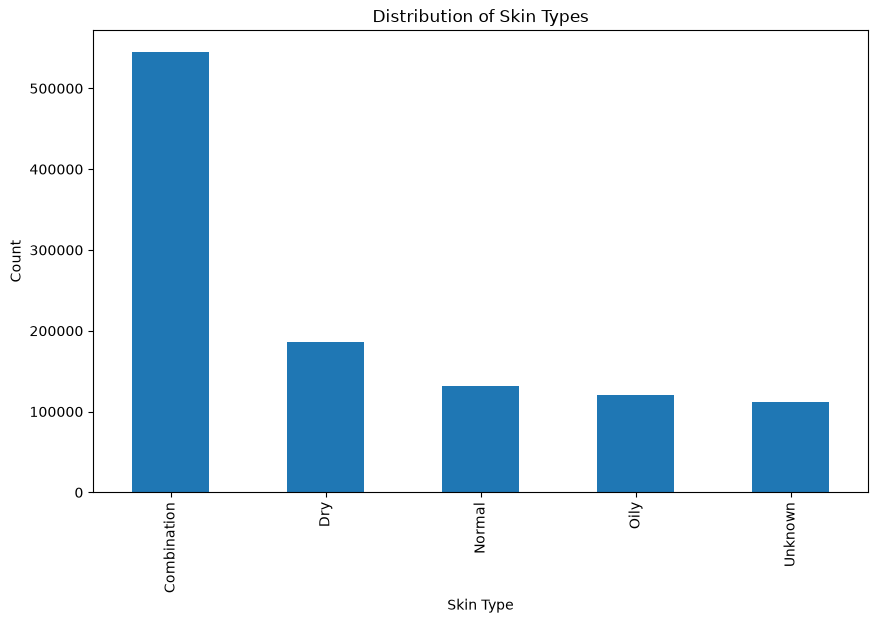

In [5]:
# Check the skin types distribution and missing values
print(df["skin_type"].value_counts(dropna=False))
print(df["skin_type"].isna().mean())

# Fill missing skin types with "unknown"
df["skin_type"] = (
    df["skin_type"]
      .fillna("Unknown")
      .str.title()
)

# Plot the distribution of skin types
plt.figure(figsize=(10, 6))
df["skin_type"].value_counts(dropna=False).plot(kind='bar')
plt.title("Distribution of Skin Types")
plt.xlabel("Skin Type")
plt.ylabel("Count")
print(df["skin_type"].dtype)

### Step 5: Explore product categories and decide what to exclude

Explore product categories and remove non-skincare categories (Wellness, High Tech Tools, and Value & Gift Sets) while keeping Mini Size products because they represent travel-size versions of skincare products. `primary_category` is 100% `Skincare` (this dataset is already skincare-only), so no filtering
needed there. 

In [6]:
print(df["primary_category"].value_counts())
print(df["secondary_category"].value_counts())
print(df["tertiary_category"].value_counts(dropna=False))

primary_category
Skincare    1094411
Name: count, dtype: int64
secondary_category
Moisturizers              297399
Treatments                222042
Cleansers                 200604
Mini Size                  85498
Eye Care                   74999
Masks                      70531
Lip Balms & Treatments     61688
Sunscreen                  41139
Value & Gift Sets          12099
Self Tanners               11942
Wellness                   10530
High Tech Tools             5925
Shop by Concern               15
Name: count, dtype: int64
tertiary_category
Moisturizers                 206124
Face Serums                  174600
NaN                          161256
Face Wash & Cleansers        121722
Eye Creams & Treatments       70440
Face Masks                    66835
Face Oils                     41858
Face Sunscreen                39088
Toners                        35860
Mists & Essences              31658
Facial Peels                  27757
Exfoliators                   26846
Blemish & Acn

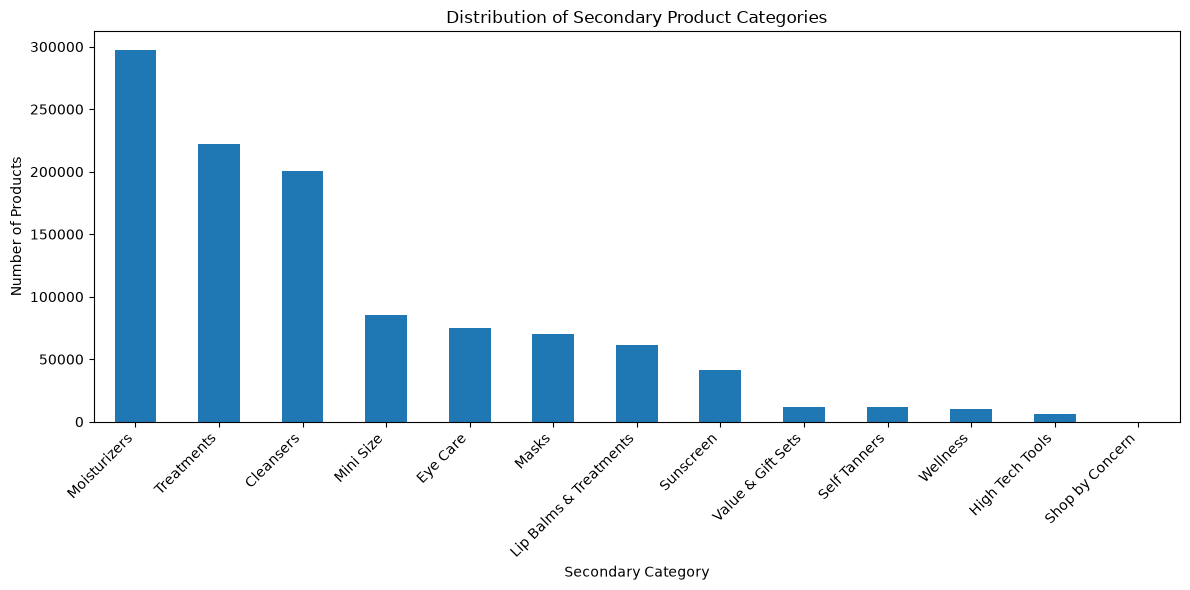

In [7]:
# Visualize secondary product categories

plt.figure(figsize=(12, 6))

df["secondary_category"].value_counts().plot(kind="bar")

plt.title("Distribution of Secondary Product Categories")
plt.xlabel("Secondary Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Decision:** exclude `Wellness`, `High Tech Tools`, `Value & Gift Sets` (secondary category), and
`Beauty Supplements`, `Teeth Whitening`, `Hair Removal`, `Facial Cleansing Brushes`, `Facial Rollers`
(tertiary category) — these are devices, ingestibles, or bundles rather than single topical skincare
products.

`Mini Size` (secondary category) was checked separately — its `tertiary_category` is entirely `NaN`,
so I inspected product names directly to confirm these are just travel-size versions of normal
skincare products (e.g. "Mini Anti-Aging Cleansing Gel"), not a distinct product type. **`Mini Size` stays in.**

In [8]:
# Confirm Mini Size is just travel-size versions of normal products, not a distinct type
print(df[df["secondary_category"] == "Mini Size"]["tertiary_category"].value_counts(dropna=False))
print(df[df["secondary_category"] == "Mini Size"]["product_name"].drop_duplicates().head(10))

tertiary_category
NaN    85498
Name: count, dtype: int64
79158                   Mini Superfood Antioxidant Cleanser
106728    Mini Cicapair Tiger Grass Color Correcting Tre...
116492                   Mini Daily Microfoliant Exfoliator
152556    Mini Take The Day Off Cleansing Balm Makeup Re...
165288                                 Mini The Water Cream
209219      Mini Watermelon Glow PHA + BHA Pore-Tight Toner
219095                   Mini Unseen Sunscreen SPF 40 PA+++
306154    Mini Ultra Facial Moisturizing Cream with Squa...
323509                Mini Acne Control Clarifying Cleanser
325958               Mini Rice Wash Skin-Softening Cleanser
Name: product_name, dtype: str


In [ ]:
# Apply category filtering 
exclude_categories = ["Wellness", "High Tech Tools", "Value & Gift Sets"]
exclude_tertiary = ["Beauty Supplements", "Teeth Whitening", "Hair Removal",
                     "Facial Cleansing Brushes", "Facial Rollers"]

before = df.shape[0]

# Keep only rows where BOTH the secondary and tertiary category are not in the exclude lists
df = df[
    ~df["secondary_category"].isin(exclude_categories) &
    ~df["tertiary_category"].isin(exclude_tertiary)
]
print(f"Category filter: {before} -> {df.shape[0]} (dropped {before - df.shape[0]})")

Category filter: 1094411 -> 1065857 (dropped 28554)


### Step 6: Clean text data

Cleans raw review text by decoding HTML entities, stripping HTML tags, and normalizing whitespace.


In [ ]:
def clean_review_text(text):

    if not isinstance(text, str):
        return ""
    
    # decode HTML entities (&amp; -> &, &nbsp; -> space)
    text = html.unescape(text)
    
    # remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    
    # replace multiple spaces, tabs, or newlines with a single space
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

df['review_text'] = df['review_text'].apply(clean_review_text)

### Step 7: Check review text quality (nulls, length, junk data) 

Remove empty reviews, obvious test entries, and reviews shorter than three words while preserving punctuation for transformer-based models.

In [11]:
# Check for nulls and empty strings in the review_text column
print("Nulls:", df["review_text"].isna().sum())

# Check for empty or whitespace-only strings
print("Empty/whitespace:", (df["review_text"].str.strip() == "").sum())

# Review length distribution (in words)
review_lengths = df["review_text"].dropna().str.split().str.len()
print(review_lengths.describe())

# How many reviews are very short, at a few candidate thresholds?
print("Reviews with < 3 words:", (review_lengths < 3).sum())
print("Reviews with < 5 words:", (review_lengths < 5).sum())
print("Reviews with < 10 words:", (review_lengths < 10).sum())

Nulls: 0
Empty/whitespace: 1414
count    1.065857e+06
mean     6.032094e+01
std      4.328210e+01
min      0.000000e+00
25%      3.200000e+01
50%      5.000000e+01
75%      7.600000e+01
max      9.820000e+02
Name: review_text, dtype: float64
Reviews with < 3 words: 1539
Reviews with < 5 words: 3069
Reviews with < 10 words: 17084


**Decision:** drop nulls and reviews under 3 words (true noise like "Great!"). Keep 3-10 word
reviews — short, but can still carry real aspect+sentiment signal (e.g. "broke me out immediately").

In [ ]:
# Apply text length filter
before = df.shape[0]
df = df[df["review_text"].notna()]
df = df[df["review_text"].str.split().str.len() >= 3]
print(f"Text length filter: {before} -> {df.shape[0]} (dropped {before - df.shape[0]})")

# Drop test rows found during inspection
before = df.shape[0]
df = df[df["review_text"] != "review message autotest"]
print(f"Test text filter: {before} -> {df.shape[0]} (dropped {before - df.shape[0]})")

Text length filter: 1065857 -> 1064318 (dropped 1539)
Test text filter: 1064318 -> 1064305 (dropped 13)


### Step 8: Check the `rating` column

Examine the star-rating imbalance and confirm that most reviews are positive - it proofs that aspect-based sentiment analysis instead of relying on ratings alone -> (use to describe the goal of proejct)

rating
1     58912
2     51560
3     79508
4    194177
5    680148
Name: count, dtype: int64
count    1.064305e+06
mean     4.301402e+00
std      1.146677e+00
min      1.000000e+00
25%      4.000000e+00
50%      5.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: rating, dtype: float64


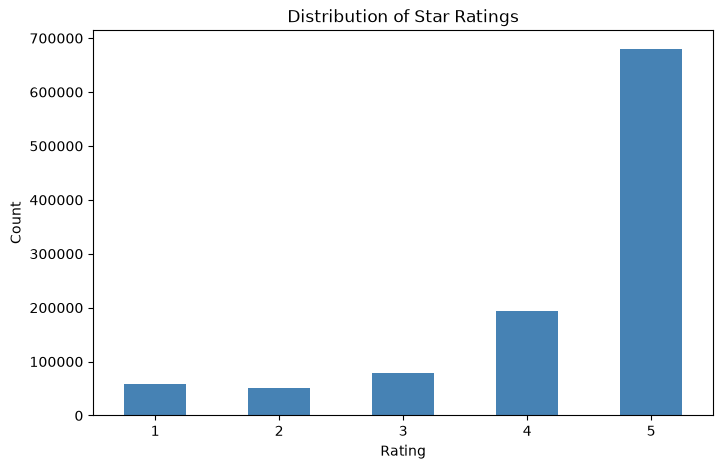

In [ ]:
# Check the distribution of ratings 
print(df["rating"].value_counts(dropna=False).sort_index())
print(df["rating"].describe())

# Note: 63.9% of reviews are 5-star and 82.1% are 4-5 stars — this heavy positive skew is
# exactly why star rating alone hides a lot of nuance and motivates the aspect-based approach.

# Plot the distribution of ratings
plt.figure(figsize=(8, 5))
df["rating"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Distribution of Star Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Step 9: Remove exact duplicate reviews (same author + product + text)

The same review recorded multiple times for the same author/product pair (could be jus scraping artifacts )

In [ ]:
# Check how many exact duplicate rows are there and how big are the groups
exact_dupe_mask = df.duplicated(subset=["author_id", "product_id", "review_text"], keep=False)
print("Exact duplicate rows found:", exact_dupe_mask.sum())

# Group the duplicates by author_id, product_id, and review_text to see how many unique duplicate groups exist
dupe_groups = df[exact_dupe_mask].groupby(["author_id", "product_id", "review_text"]).size()
print("Number of duplicate groups:", dupe_groups.shape[0])
print(dupe_groups.sort_values(ascending=False).head(10))

Exact duplicate rows found: 948
Number of duplicate groups: 407
author_id   product_id  review_text                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 
2048600043  P377368     I received this in a sample. I have alot of acne scars. This serum works it doesn’t happen overnight. SO HAVE PATIENCE. I have noticed my scars are lightening and it’s so nice. I have tried everyrhing from drug store brands to presrciption medication wirh no results.

In [ ]:
# Drop exact duplicates, keep one row per group
before = df.shape[0]
df = df.drop_duplicates(subset=["author_id", "product_id", "review_text"], keep="first")
print(f"Exact duplicate drop: {before} -> {df.shape[0]} (dropped {before - df.shape[0]})")

Exact duplicate drop: 1064305 -> 1063764 (dropped 541)


### Step 10: Investigate and remove duplicate reviews across products

There are repeated reviews across products. Find cases where the same author posted the exact same review text more than once. This helps find out if these are genuine duplicate (e.g g mini vs full-size products) or independent reviews

In [ ]:
# Investigate duplicate reviews across product listings
group_sizes = (
    df.groupby(["author_id", "review_text"])
      .size()
)

# Keep only duplicate groups (appearing more than once)
duplicate_groups = group_sizes[group_sizes > 1]

print("Distribution of (author_id, review_text) duplicate-group sizes:")
print(duplicate_groups.value_counts().sort_index())
print("Total duplicate groups:", duplicate_groups.shape[0])
print("Total rows involved:", duplicate_groups.sum())


# Inspect few examples to verify whether they are true duplicates
sample_groups = duplicate_groups.sample(5, random_state=42).index

for author, text in sample_groups:
    print("\n" + "=" * 80)
    print(f"Author: {author}")

    display(
        df.loc[
            (df["author_id"] == author) &
            (df["review_text"] == text),
            [
                "product_name",
                "brand_name",
                "secondary_category",
                "submission_time",
                "rating"
            ]
        ]
    )

Distribution of (author_id, review_text) duplicate-group sizes:
2     111870
3       3568
4         53
5         37
6          7
7          5
8          1
9          1
14         1
19         1
Name: count, dtype: int64
Total duplicate groups: 115544
Total rows involved: 234968

Author: 2022442303


,product_name,brand_name,secondary_category,submission_time,rating
245179,Oat Cleansing Balm,The INKEY List,Cleansers,2022-05-04,1
248179,Mini Oat Cleansing Balm,The INKEY List,Cleansers,2022-05-04,1



Author: 7671067520


,product_name,brand_name,secondary_category,submission_time,rating
218812,Unseen Sunscreen SPF 40 PA+++,Supergoop!,Sunscreen,2018-08-13,4
222078,Mini Unseen Sunscreen SPF 40 PA+++,Supergoop!,Mini Size,2018-08-13,4



Author: 27996091702


,product_name,brand_name,secondary_category,submission_time,rating
55368,Green Clean Makeup Removing Cleansing Balm,Farmacy,Cleansers,2022-04-15,5
61537,Green Clean Makeup Meltaway Cleansing Balm Lim...,Farmacy,Cleansers,2022-04-15,5



Author: 10076895231


,product_name,brand_name,secondary_category,submission_time,rating
100911,Cicapair Tiger Grass Color Correcting Treatmen...,Dr. Jart+,Moisturizers,2017-09-17,5
111146,Mini Cicapair Tiger Grass Color Correcting Tre...,Dr. Jart+,Mini Size,2017-09-17,5



Author: 2347190333


,product_name,brand_name,secondary_category,submission_time,rating
283409,Revitalizing Supreme+ Youth Power Creme Moistu...,Estée Lauder,Moisturizers,2022-09-03,3
286192,Mini Revitalizing Supreme+ Youth Power Creme M...,Estée Lauder,Moisturizers,2022-09-03,3


In [ ]:
# Remove duplicate reviews only when the same author posted the same review text with the same submission date and rating.
before = df.shape[0]

df = df.drop_duplicates(
    subset=[
        "author_id",
        "review_text",
        "submission_time",
        "rating"
    ],
    keep="first"
)

after = df.shape[0]

print(f"Safe duplicate removal: {before:,} → {after:,}")
print(f"Removed {before-after:,} rows")

remaining = df.duplicated(
    subset=[
        "author_id",
        "review_text",
        "submission_time",
        "rating"
    ],
    keep=False
).sum()

print("Remaining safe-duplicate rows:", remaining)

Safe duplicate removal: 1,063,764 → 944,536
Removed 119,228 rows
Remaining safe-duplicate rows: 0


### Step 11: Filter Non-English Reviews

In [ ]:

DetectorFactory.seed = 0

# Function to check if a review is in English (using langdetect)
def is_english_review(text):
    """
    Checks if a review text is in English. 
    Returns True if English, False otherwise.
    """
    if not isinstance(text, str) or len(text.strip()) < 3:
        return False
    try:
        return detect(text) == 'en'
    except LangDetectException:
        # if fails to determine the language (e.g., emojis only) - filter it out
        return False

print("Running language detection...")

# Create a boolean mask for English reviews
is_eng = df['review_text'].apply(is_english_review)

# Calculate stats
total_before_lang = len(df)
non_english_count = total_before_lang - is_eng.sum()
print(f"-> Total reviews before language filter: {total_before_lang:,}")
print(f"-> Found {non_english_count:,} non-English reviews (will be removed).")

# Apply the filter to keep only English reviews
df = df[is_eng]

Running language detection...
-> Total reviews before language filter: 944,536
-> Found 3,895 non-English reviews (will be removed).


### Step 12: Select the columns needed for aspect/sentiment modeling

Keep only the features required for the next phase, including review text, rating, skin type, product metadata, and engagement metrics.


In [19]:
# Core review content and labels
review_cols = [
    "author_id", "review_text", "review_title", "rating", "skin_type",
    "submission_time", "is_recommended", "helpfulness", "total_feedback_count",
]

# Product identity and context
product_cols = [
    "product_id", "product_name", "brand_name",
    "primary_category", "secondary_category", "tertiary_category", 
]


keep_cols = review_cols + product_cols

df_model = df[keep_cols].copy()

print("Columns kept:", df_model.shape[1])
print(df_model.columns.tolist())
print(df_model.shape)
df_model.head()

Columns kept: 15
['author_id', 'review_text', 'review_title', 'rating', 'skin_type', 'submission_time', 'is_recommended', 'helpfulness', 'total_feedback_count', 'product_id', 'product_name', 'brand_name', 'primary_category', 'secondary_category', 'tertiary_category']
(940641, 15)


,author_id,review_text,review_title,rating,skin_type,submission_time,is_recommended,helpfulness,total_feedback_count,product_id,product_name,brand_name,primary_category,secondary_category,tertiary_category
0,1741593524,I use this with the Nudestix “Citrus Clean Bal...,Taught me how to double cleanse!,5,Dry,2023-02-01,1.0,1.0,2,P504322,Gentle Hydra-Gel Face Cleanser,NUDESTIX,Skincare,Cleansers,NaN
1,31423088263,I bought this lip mask after reading the revie...,Disappointed,1,Unknown,2023-03-21,0.0,NaN,0,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Skincare,Lip Balms & Treatments,NaN
2,5061282401,My review title says it all! I get so excited ...,New Favorite Routine,5,Dry,2023-03-21,1.0,NaN,0,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Skincare,Lip Balms & Treatments,NaN
3,6083038851,I’ve always loved this formula for a long time...,Can't go wrong with any of them,5,Combination,2023-03-20,1.0,NaN,0,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Skincare,Lip Balms & Treatments,NaN
4,47056667835,"If you have dry cracked lips, this is a must h...",A must have !!!,5,Combination,2023-03-20,1.0,NaN,0,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Skincare,Lip Balms & Treatments,NaN


### Step 13: Save the cleaned dataset

Save the final processed dataset as skincare_reviews_clean.csv for aspect detection and sentiment modeling.

In [20]:
df_model.to_csv("skincare_reviews_clean.csv", index=False)
print("Saved:", df_model.shape)

Saved: (940641, 15)


# Phase 1 Summary: Data Loading and Merge Setup

In this phase, I prepared the raw review dataset for downstream aspect-level sentiment modeling.

- Loaded all review CSV files into a single pandas DataFrame to combine the segmented data.
- Loaded the product metadata and normalized `product_id` values to ensure consistent joining.
- Removed duplicate product entries to keep the product reference table clean.
- Merged review records with product information using `product_id` to enrich each review with product details.
- Verified that the merge preserved the original review count and checked for unmatched products.
- Inspected the resulting DataFrame schema and sample records to confirm the data was ready for cleaning and feature selection.

This phase created the foundation for the next steps: data cleaning, feature preparation, and model development.